# Toy Data Generation

Data for spectrascope should be formed in the following way.

We assume there are:
- N spectra, each with length M and *one dimensional* response variable y
- One single length M X-axis, which describes the shared axis that all spectra have.

The spectra are grouped together in a matrix that is N+1 x N+1.
- The final column for the first N rows, marked 'y', contains the 'response' variable for the spectrum in that row.
- The final row, marked 'x-axis', contains the grid values that the N spectra 'above' it live on. The final value is a nan and is not used for anything.


Here, we prepare a toy data set of different randomly generated superpositions of sine waves in the interval $[0,2\pi]$, where the response variable is the value of the third harmonic i.e. that of the wavelength $\frac{3L}{2 \pi} = 3$ as $L=2 \pi$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_signal(x_axis, a1, a2, a3, a4):
    return a1*np.sin(x_axis) + a2*np.sin(2*x_axis) + a3*np.sin(3*x_axis) + a4*np.sin(4*x_axis)

M = 200
x_axis = np.linspace(0,2*np.pi,M)

N = 100
signal_coefficients = np.random.rand(N,4)

signals = np.zeros((N,M))

# Generate N signals by mapping the generate_signal function into N rows of the signals matrix
for i in range(N):
    signals[i] = generate_signal(x_axis, *signal_coefficients[i,:])

# Append the a3 coefficient to the right end of the signals matrix
signals = np.hstack((signals, signal_coefficients[:,2].reshape(-1,1)))

# Add the x axis to the end of the signals matrix

x_axis_with_nan = np.append(x_axis,np.nan).reshape(1,-1)
signals = np.vstack((signals, x_axis_with_nan))


# Save as a pandas dataframe, where the rows are indexed 0-99 and then the final row is called x-axis,
# and the columns are indexed 0-100 with the final column called y
import pandas as pd
df = pd.DataFrame(signals)
df.index = df.index.astype(str)
df.columns = df.columns.astype(str)
df.columns.values[-1] = 'y'
df.index.values[-1] = 'x-axis'
df.to_csv("sample.csv")

# Print df
print(df)
#print the final column of the dataframe's values
print(df['y'].values)


          0         1         2         3         4         5         6  \
0       0.0  0.192071  0.382437  0.569412  0.751351  0.926668  1.093855   
1       0.0  0.178568  0.355062  0.527439  0.693711  0.851981  1.000461   
2       0.0  0.203097  0.404601  0.602935  0.796557  0.983976  1.163769   
3       0.0  0.126888  0.253028  0.377677  0.500106  0.619606  0.735492   
4       0.0  0.094650  0.188486  0.280705  0.370518  0.457159  0.539895   
...     ...       ...       ...       ...       ...       ...       ...   
96      0.0  0.206820  0.411325  0.611233  0.804322  0.988461  1.161639   
97      0.0  0.054967  0.109519  0.163246  0.215750  0.266648  0.315581   
98      0.0  0.105805  0.210759  0.314018  0.414762  0.512195  0.605562   
99      0.0  0.154947  0.308383  0.458815  0.604786  0.744891  0.877797   
x-axis  0.0  0.031574  0.063148  0.094721  0.126295  0.157869  0.189443   

               7         8         9  ...       191       192       193  \
0       1.251498  1.3982

In [2]:
signals.shape

(101, 201)

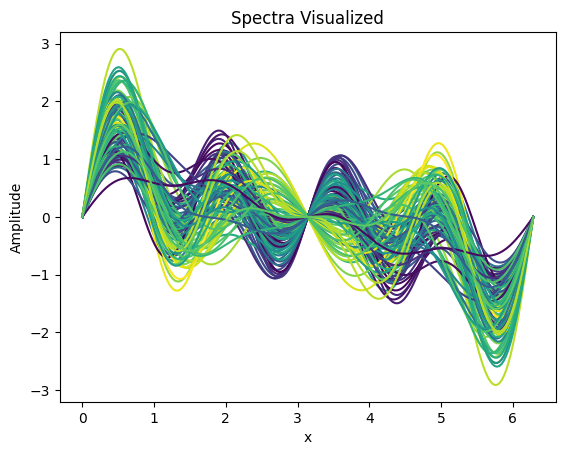

In [3]:
# Plot the signals, colored by the value of the final value of the signals matrix

x_axis = signals[-1,:]
sigs = signals[:-1,:]

for sig in sigs:
    plt.plot(x_axis[:-1], sig[:-1],color=plt.cm.viridis(sig[-1]))
    plt.title("Spectra Visualized")
    plt.xlabel("x")
    plt.ylabel("Amplitude")
plt.show()

## Load the data for use with SpectraScope class

In [7]:
from home import load_pdf_xanes_data, load_wine_data, load_custom_data

In [8]:
px_data = load_pdf_xanes_data()
for i, sn in enumerate(px_data.specnames):
    print(i, sn, px_data.X[i].shape, px_data.spec_metadata[sn].xaxis.shape)
print(px_data.y.shape)
print(px_data.yname)

0 pdf (821, 200) (200,)
1 xanes (821, 200) (200,)
(821,)
nn


In [9]:
wine_data = load_wine_data()
for i, sn in enumerate(wine_data.specnames):
print(wine_data.y.shape)
print(wine_data.yname)

0 nir (172, 2151) (2151,)
1 rm (172, 1974) (1974,)
(172,)
br


In [21]:
from streamlit.runtime.uploaded_file_manager import UploadedFile,UploadedFileRec
import pathlib

# Create a streamlit UploadedFile
sample_csv = UploadedFile(
    record=UploadedFileRec(
        file_id=-1,
        name="sample.csv",
        type=None,
        data=pathlib.Path("sample.csv").read_bytes()
    ),
    file_urls=[]
)

custom_data = load_custom_data([sample_csv])
for i, sn in enumerate(custom_data.specnames):
    print(i, sn, custom_data.X[i].shape, custom_data.spec_metadata[sn].xaxis.shape)
print(custom_data.y.shape)
print(custom_data.yname)



0 sample (100, 200) (200,)
(100,)
yname
